# Sparse Teacher Features

**Question:** In 07, centering keeps teacher 2's unused units firing only because they fire 50% of the time, where the push on their bias starts near 0. Does the forgetting come back with centering when teacher LTUs fire 20% of the time?

Same setup as 07, except every teacher LTU fires when $w \cdot x > 4$, which is 19.2% of inputs. A unit counts as off when it fires on fewer than 2% of 2000 random inputs.

In [1]:
from functools import partial
from time import perf_counter
from typing import NamedTuple

import jax
jax.config.update('jax_platforms', 'cuda')
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np

from phd.jax_core.models import ltu
from phd.jax_core.optimizers.idbd import optax_idbd

%matplotlib inline
assert jax.default_backend() == 'gpu'

/home/edan/miniconda3/envs/jax/lib/python3.10/site-packages/pydantic/_internal/_generate_schema.py:2274: UnsupportedFieldAttributeWarning: The 'repr' attribute with value False was provided to the `Field()` function, which has no effect in the context it was used. 'repr' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an `Annotated` type alias using the `type` statement was used, or if the `Field()` function was attached to a single member of a union type.
  warnings.warn(
/home/edan/miniconda3/envs/jax/lib/python3.10/site-packages/pydantic/_internal/_generate_schema.py:2274: UnsupportedFieldAttributeWarning: The 'frozen' attribute with value True was provided to the `Field()` function, which has no effect in the context it was used. 'frozen' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an 

In [2]:
# Problem: 05's schedule, through AFTER_STEPS steps past the 1-task phase
N_INPUTS, WIDTH, N_OUTPUTS = 21, 10, 10
N_TASKS, N_HIDDEN = 4, 2 * WIDTH
THRESHOLD = 4  # teacher LTUs fire when w·x > THRESHOLD: 19.2% of inputs
ACTIVE = (4, 3, 2, 1, 2)
GAP = ACTIVE.index(1)  # the 1-task phase
PHASE_STEPS, AFTER_STEPS = 500_000, 60_000

# Learners
SGD_RATE = 2.**-6
INIT_RATE, META_RATE, EMA_RATE = np.exp(-8.), 0.02, 1e-3
OFF = .02  # a unit is off if it fires on fewer than OFF of the probe inputs
PROBE = jnp.asarray(np.random.default_rng(0).choice([-1., 1.], (2000, N_INPUTS)), dtype=jnp.float32)

PERIOD, WINDOW, N_SEEDS = 10_000, 1000, 5

## Task

In [3]:
def init_teacher(key):
    input_key, _, output_key = jax.random.split(key, 3)
    w = jax.random.rademacher(input_key, (WIDTH, N_INPUTS), dtype=jnp.float32)
    v = jax.random.rademacher(output_key, (N_OUTPUTS, WIDTH), dtype=jnp.float32)
    return w, v


def target(teacher, x):
    w, v = teacher
    return v @ (w @ x > THRESHOLD).astype(jnp.float32)

## Learners

In [4]:
OPTIMIZER = optax_idbd(meta_lr=META_RATE, init_lr=INIT_RATE, autostep=True, tau=1e4, version='squared_inputs')
FROZEN = optax_idbd(meta_lr=0., init_lr=INIT_RATE, autostep=True, tau=1e4, version='squared_inputs')


class Learner(NamedTuple):
    weights: tuple
    opt: object
    mean: jax.Array
    slope: jax.Array


def init_learner(key, method):
    bound = INIT_RATE if method == 'Autostep' else np.sqrt(3 / N_INPUTS)
    w = jax.random.uniform(key, (N_HIDDEN, N_INPUTS + 1), minval=-bound, maxval=bound).at[:, -1].set(0.)
    weights = (w, jnp.zeros((N_OUTPUTS, N_HIDDEN + 1)))
    return Learner(weights, OPTIMIZER.init(weights) if method == 'Autostep' else None,
                   jnp.full(N_HIDDEN, .5), jnp.zeros_like(w).at[:, -1].set(.25))


def forward(weights, x, learner, centered):
    source = jnp.append(x, 1.)
    z = weights[0] @ source
    h, mean, slope = ltu(z), learner.mean, learner.slope
    if centered:
        # Same uncompensated centering and centered surrogate as 05.
        mean = mean + EMA_RATE * (jax.lax.stop_gradient(h) - mean)
        sigmoid = jax.nn.sigmoid(z)
        slope = slope + EMA_RATE * (jax.lax.stop_gradient(sigmoid * (1 - sigmoid))[:, None] * source - slope)
        correction = jnp.sum(slope * weights[0], axis=1)
        h = h - mean + (jax.lax.stop_gradient(correction) - correction)
    hidden = jnp.append(h, 1.)
    return weights[1] @ hidden, ((source[None], hidden[None]), mean, slope)


def update(learner, x, y, method, centered, optimizer):
    def loss(weights):
        prediction, aux = forward(weights, x, learner, centered)
        return .5 * jnp.sum((prediction - y) ** 2), aux
    (loss_value, (sources, mean, slope)), grads = jax.value_and_grad(loss, has_aux=True)(learner.weights)
    if method == 'Autostep':
        updates, opt = optimizer.update((grads, None, sources), learner.opt, learner.weights)
    else:
        updates, opt = jax.tree.map(lambda g: -SGD_RATE * g, grads), None
    return Learner(jax.tree.map(jnp.add, learner.weights, updates), opt, mean, slope), 2 * loss_value / N_OUTPUTS

## Training

In [5]:
def train(seed, gap_noise, method, centered, freeze):
    teacher_key, learner_key, schedule_key, rng = jax.random.split(jax.random.PRNGKey(seed), 4)
    teachers = jax.vmap(init_teacher)(jax.random.split(teacher_key, N_TASKS))
    active = jnp.repeat(jnp.array(ACTIVE), PHASE_STEPS // PERIOD)
    probe = jnp.append(PROBE, jnp.ones((len(PROBE), 1)), axis=1)

    def run_blocks(carry, block_ids, noise, optimizer):
        def block(carry, block_id):
            learner, rng, task_id = carry
            task_id = jnp.where(block_id == 0, task_id, (task_id + 1) % active[block_id])
            teacher = jax.tree.map(lambda w: w[task_id], teachers)

            def sample(carry, _):
                learner, rng = carry
                rng, x_key, noise_key = jax.random.split(rng, 3)
                x = jax.random.rademacher(x_key, (N_INPUTS,), dtype=jnp.float32)
                y = target(teacher, x) + noise * jax.random.normal(noise_key, (N_OUTPUTS,))
                learner, mse = update(learner, x, y, method, centered, optimizer)
                return (learner, rng), mse

            def record(carry, _):
                # Window mean of the MSE; fraction of hidden units that are off at the window's end.
                carry, mse = jax.lax.scan(sample, carry, length=WINDOW)
                firing = jnp.mean(probe @ carry[0].weights[0].T > 0, axis=0)
                return carry, (mse.mean(), jnp.mean(firing < OFF))

            (learner, rng), records = jax.lax.scan(record, (learner, rng), length=PERIOD // WINDOW)
            return (learner, rng, task_id), records

        carry, (mse, off) = jax.lax.scan(block, carry, block_ids)
        return carry, mse.reshape(-1), off.reshape(-1)

    blocks = PHASE_STEPS // PERIOD
    carry = (init_learner(learner_key, method), rng, jax.random.randint(schedule_key, (), 0, N_TASKS))
    carry, _, _ = run_blocks(carry, jnp.arange(GAP * blocks), 1., OPTIMIZER)
    carry, _, off = run_blocks(carry, jnp.arange(GAP * blocks, (GAP + 1) * blocks), gap_noise,
                               FROZEN if freeze else OPTIMIZER)
    _, mse, _ = run_blocks(carry, (GAP + 1) * blocks + jnp.arange(AFTER_STEPS // PERIOD), 1., OPTIMIZER)
    return off, mse  # off-fraction through the 1-task phase, MSE after it


@partial(jax.jit, static_argnames=('method', 'centered', 'freeze'))
def train_many(gap_noises, method, centered, freeze):
    one = partial(train, method=method, centered=centered, freeze=freeze)
    # Inner vmap: seeds; outer vmap: target noise in the 1-task phase.
    return jax.vmap(jax.vmap(one, in_axes=(0, None)), in_axes=(None, 0))(jnp.arange(N_SEEDS), gap_noises)


def run(gap_noises, method, centered=False, freeze=False):
    off, mse = jax.tree.map(np.asarray, train_many(jnp.asarray(gap_noises), method, centered, freeze))
    return list(zip(off, mse))

In [6]:
started = perf_counter()
runs = {'SGD': run([1.], 'SGD')[0],
        'SGD + centering': run([1.], 'SGD', centered=True)[0],
        'Autostep': run([1.], 'Autostep', centered=True)[0]}
print(f'{perf_counter() - started:.1f}s including compilation')

81.2s including compilation


## Plots

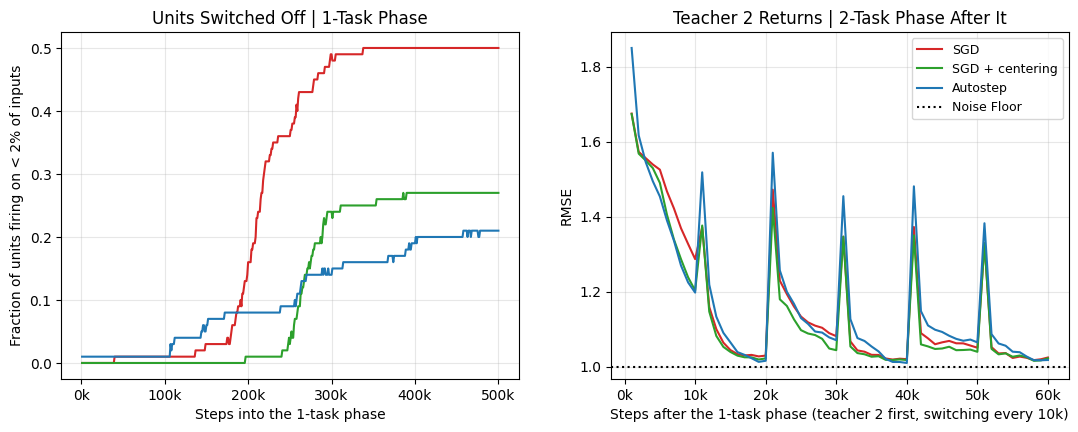

SGD: 50% of units off at the end of the 1-task phase; RMSE over steps 2k-10k of the first block back 1.437
SGD + centering: 27% of units off at the end of the 1-task phase; RMSE over steps 2k-10k of the first block back 1.380
Autostep: 21% of units off at the end of the 1-task phase; RMSE over steps 2k-10k of the first block back 1.364


In [7]:
colors = ['C3', 'C2', 'C0']
gap_x = np.arange(1, PHASE_STEPS // WINDOW + 1) * WINDOW
after_x = np.arange(1, AFTER_STEPS // WINDOW + 1) * WINDOW
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for (label, (off, mse)), color in zip(runs.items(), colors):
    axes[0].plot(gap_x, off.mean(axis=0), color=color, label=label)
    axes[1].plot(after_x, np.sqrt(mse).mean(axis=0), color=color, label=label)
axes[1].axhline(1., color='black', ls=':', label='Noise Floor')
axes[0].set(title='Units Switched Off | 1-Task Phase', xlabel='Steps into the 1-task phase',
            ylabel=f'Fraction of units firing on < {OFF:.0%} of inputs')
axes[1].set(title='Teacher 2 Returns | 2-Task Phase After It', ylabel='RMSE',
            xlabel='Steps after the 1-task phase (teacher 2 first, switching every 10k)')
for ax in axes:
    ax.xaxis.set_major_formatter(lambda t, _: f'{t / 1000:g}k')
    ax.grid(True, alpha=.3)
axes[1].legend(fontsize=9)
plt.show()
for label, (off, mse) in runs.items():
    print(f'{label}: {off[:, -1].mean():.0%} of units off at the end of the 1-task phase; '
          f'RMSE over steps 2k-10k of the first block back {np.sqrt(mse[:, 2:10]).mean():.3f}')

All curves use five paired seeds; no uncertainty bands are shown.

**Result (81.2s on GPU):** The forgetting comes back with centering. By the end of the 1-task phase, 50% of SGD's units no longer fire, against 27% with centering and 21% for Autostep (none in 07). Teacher 2 comes back slowly for all three: RMSE over steps 2k–10k of the first block back is 1.437 for SGD, 1.380 with centering and 1.364 for Autostep.